# Week 8 · Networks

Eight groups of four or five students. One hour of chat each. They are deciding which seven questions to ask a hotel owner whose guest wifi keeps failing.

1,374 messages. Translated from Spanish; the original is kept in `message_es`.

Run the cell below.

In [1]:
%matplotlib inline
import pandas as pd, networkx as nx, matplotlib.pyplot as plt, numpy as np

BASE = "https://raw.githubusercontent.com/HakeoungLee/edis8100-datasets/main"
chat = pd.read_csv(f"{BASE}/collab-chat/chat_logs_en.csv")

print(f"{len(chat):,} messages | {chat.group.nunique()} groups | {chat.author.nunique()} people")
display(chat.head(8)[["group", "author", "message"]])

1,374 messages | 8 groups | 34 people


,group,author,message
0,1,a.7jKzKFsPBtn1hT5G,hi chat
1,1,a.DiXDQxpPWP7gz4LT,hi group
2,1,a.I6ZFAmhSZ4KY2HU1,Hiii
3,1,a.7jKzKFsPBtn1hT5G,hi
4,1,a.DiXDQxpPWP7gz4LT,Okay we have quite a few questions that are ne...
5,1,a.7jKzKFsPBtn1hT5G,we have a couple of the video on demand one
6,1,a.7jKzKFsPBtn1hT5G,I'd say the budget one definitely has to be in
7,1,a.2AmxcttO04AznGqW,wow that's cool XD


## 1. Draw it

A tie is a decision. Here is the first one, and it is the obvious one:

**A and B are tied if B spoke right after A.**

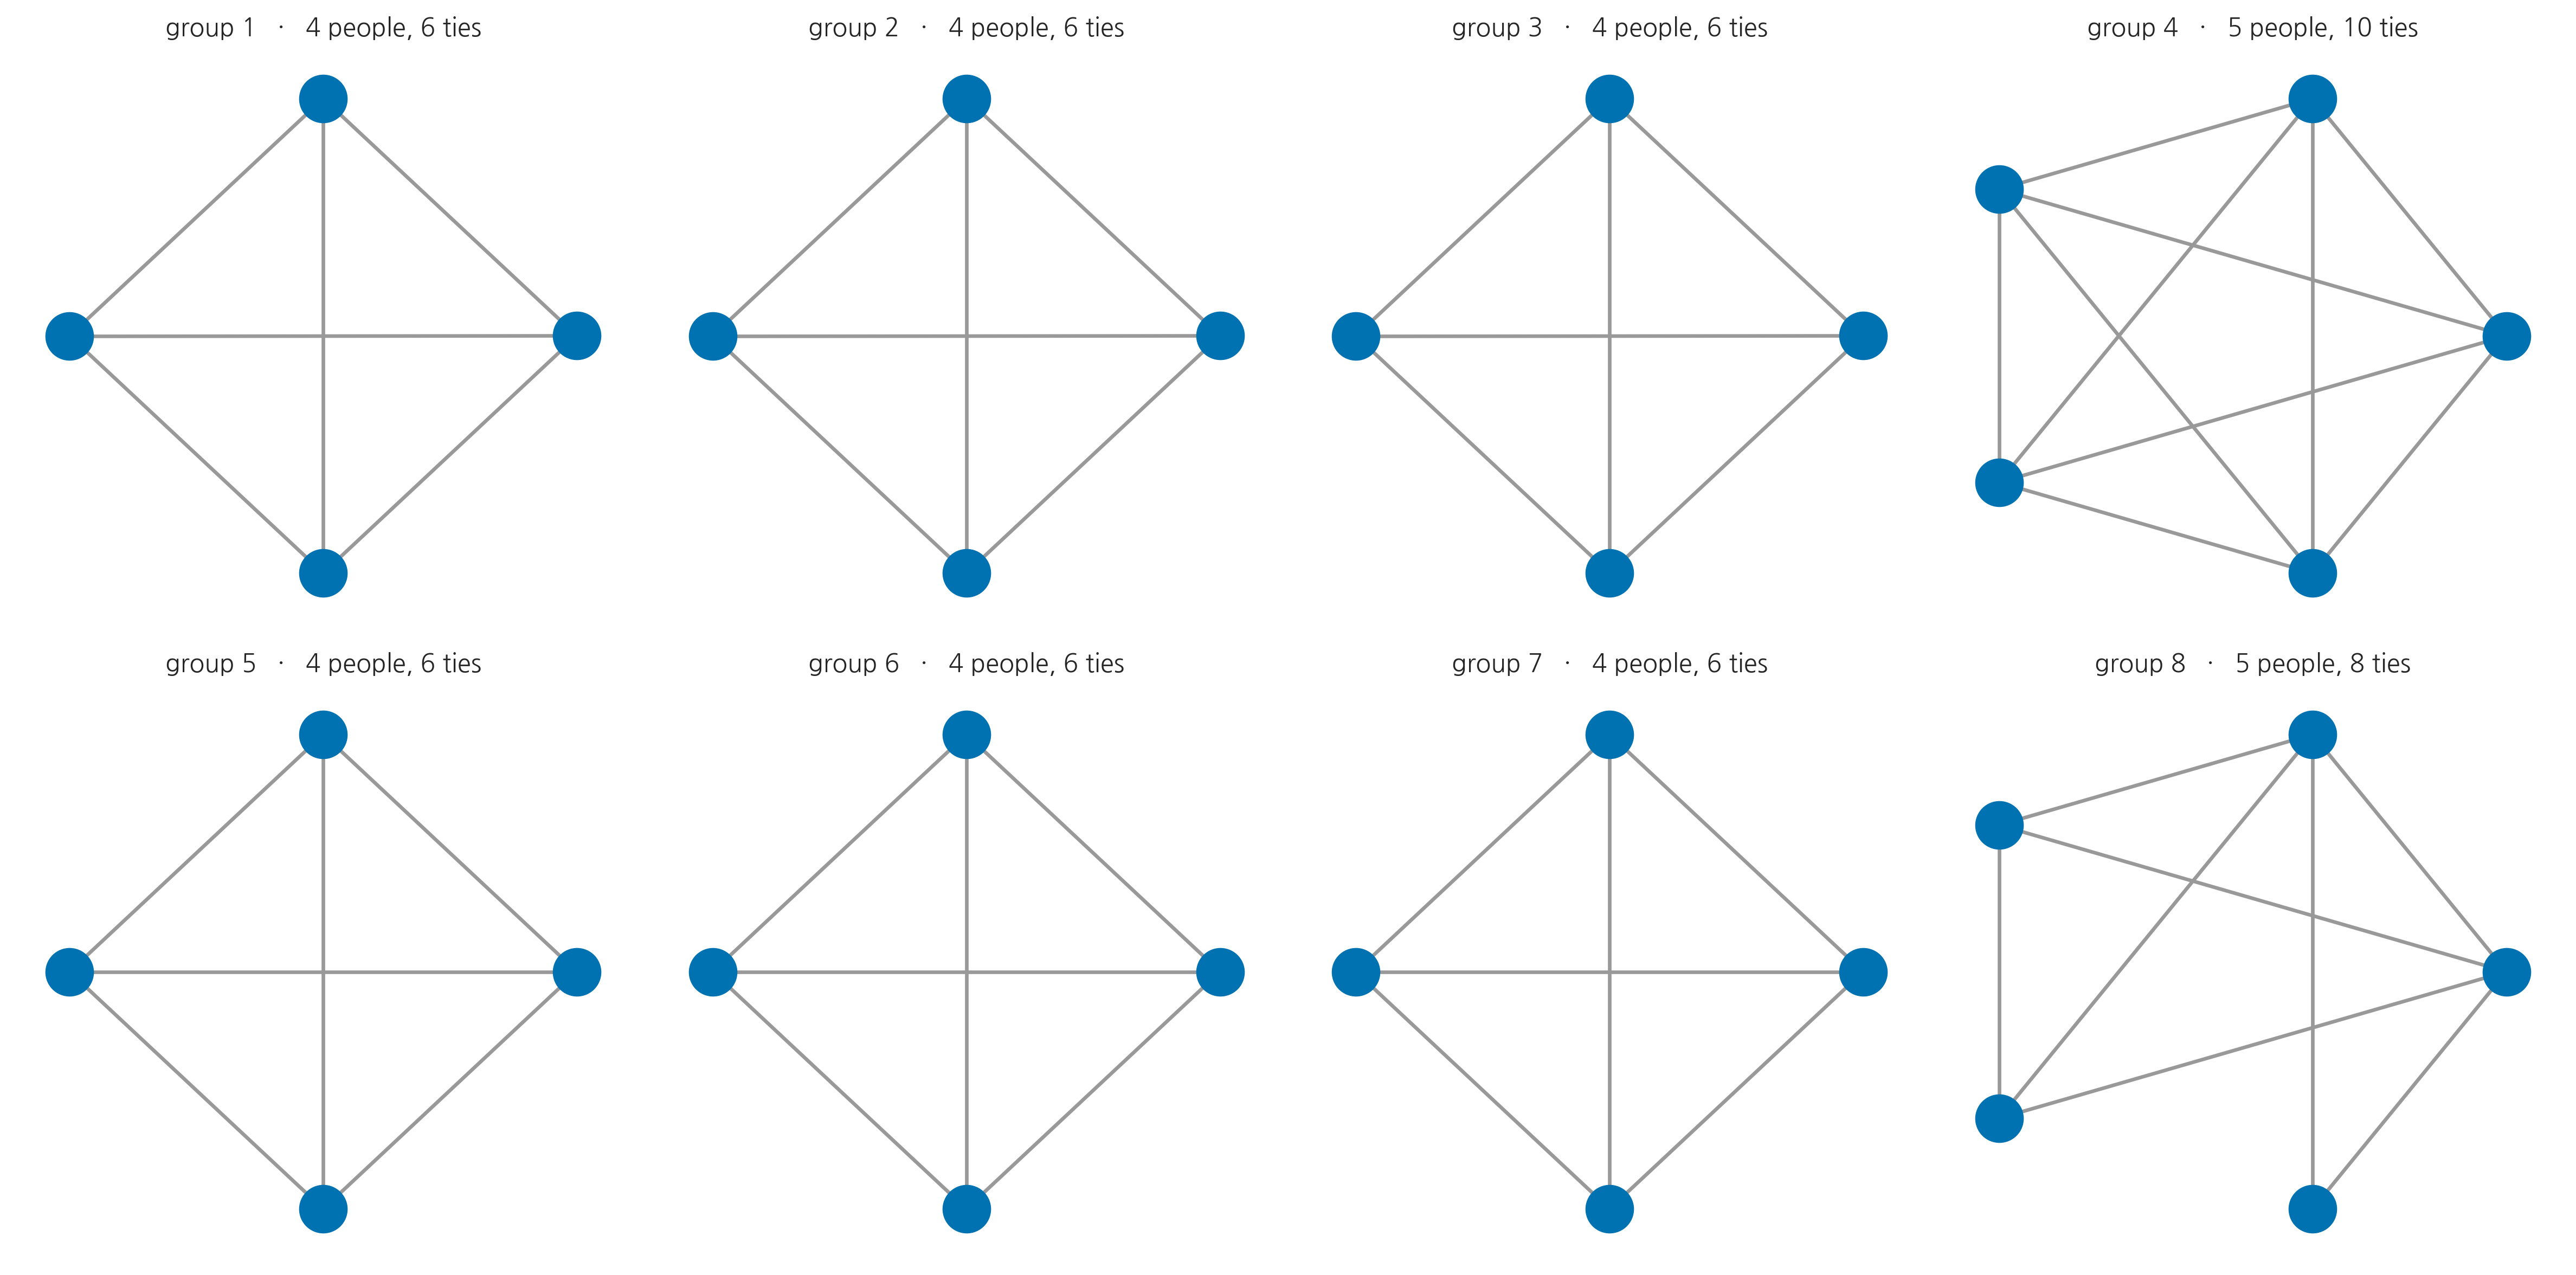

In [2]:
def ties_adjacent(sub):
    G = nx.Graph()
    G.add_nodes_from(sub.author.unique())
    for a, b in zip(sub.author[:-1], sub.author[1:]):
        if a != b:
            G.add_edge(a, b)
    return G

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (g, sub) in zip(axes.ravel(), chat.groupby("group")):
    G = ties_adjacent(sub.reset_index(drop=True))
    nx.draw(G, nx.circular_layout(G), ax=ax, node_color="#0072b2",
            node_size=420, width=1.6, edge_color="#999999")
    ax.set_title(f"group {g}   ·   {G.number_of_nodes()} people, "
                 f"{G.number_of_edges()} ties", fontsize=11)
plt.tight_layout(); plt.show()

**What do you notice?**

In [3]:
rows = []
for g, sub in chat.groupby("group"):
    G = ties_adjacent(sub.reset_index(drop=True))
    rows.append({"group": g, "people": G.number_of_nodes(), "ties": G.number_of_edges(),
                 "density": round(nx.density(G), 2),
                 "everyone tied to everyone": nx.density(G) == 1.0})
display(pd.DataFrame(rows))

,group,people,ties,density,everyone tied to everyone
0,1,4,6,1.0,True
1,2,4,6,1.0,True
2,3,4,6,1.0,True
3,4,5,10,1.0,True
4,5,4,6,1.0,True
5,6,4,6,1.0,True
6,7,4,6,1.0,True
7,8,5,8,0.8,False


## 2. The rule produced nothing

Seven of the eight are complete graphs. Everyone is tied to everyone, so every person has the same degree and the picture carries no information.

That is not a property of these students. It is a property of the rule. Four people chatting for an hour will all speak after each other eventually.

**So count the ties instead of just recording them.**

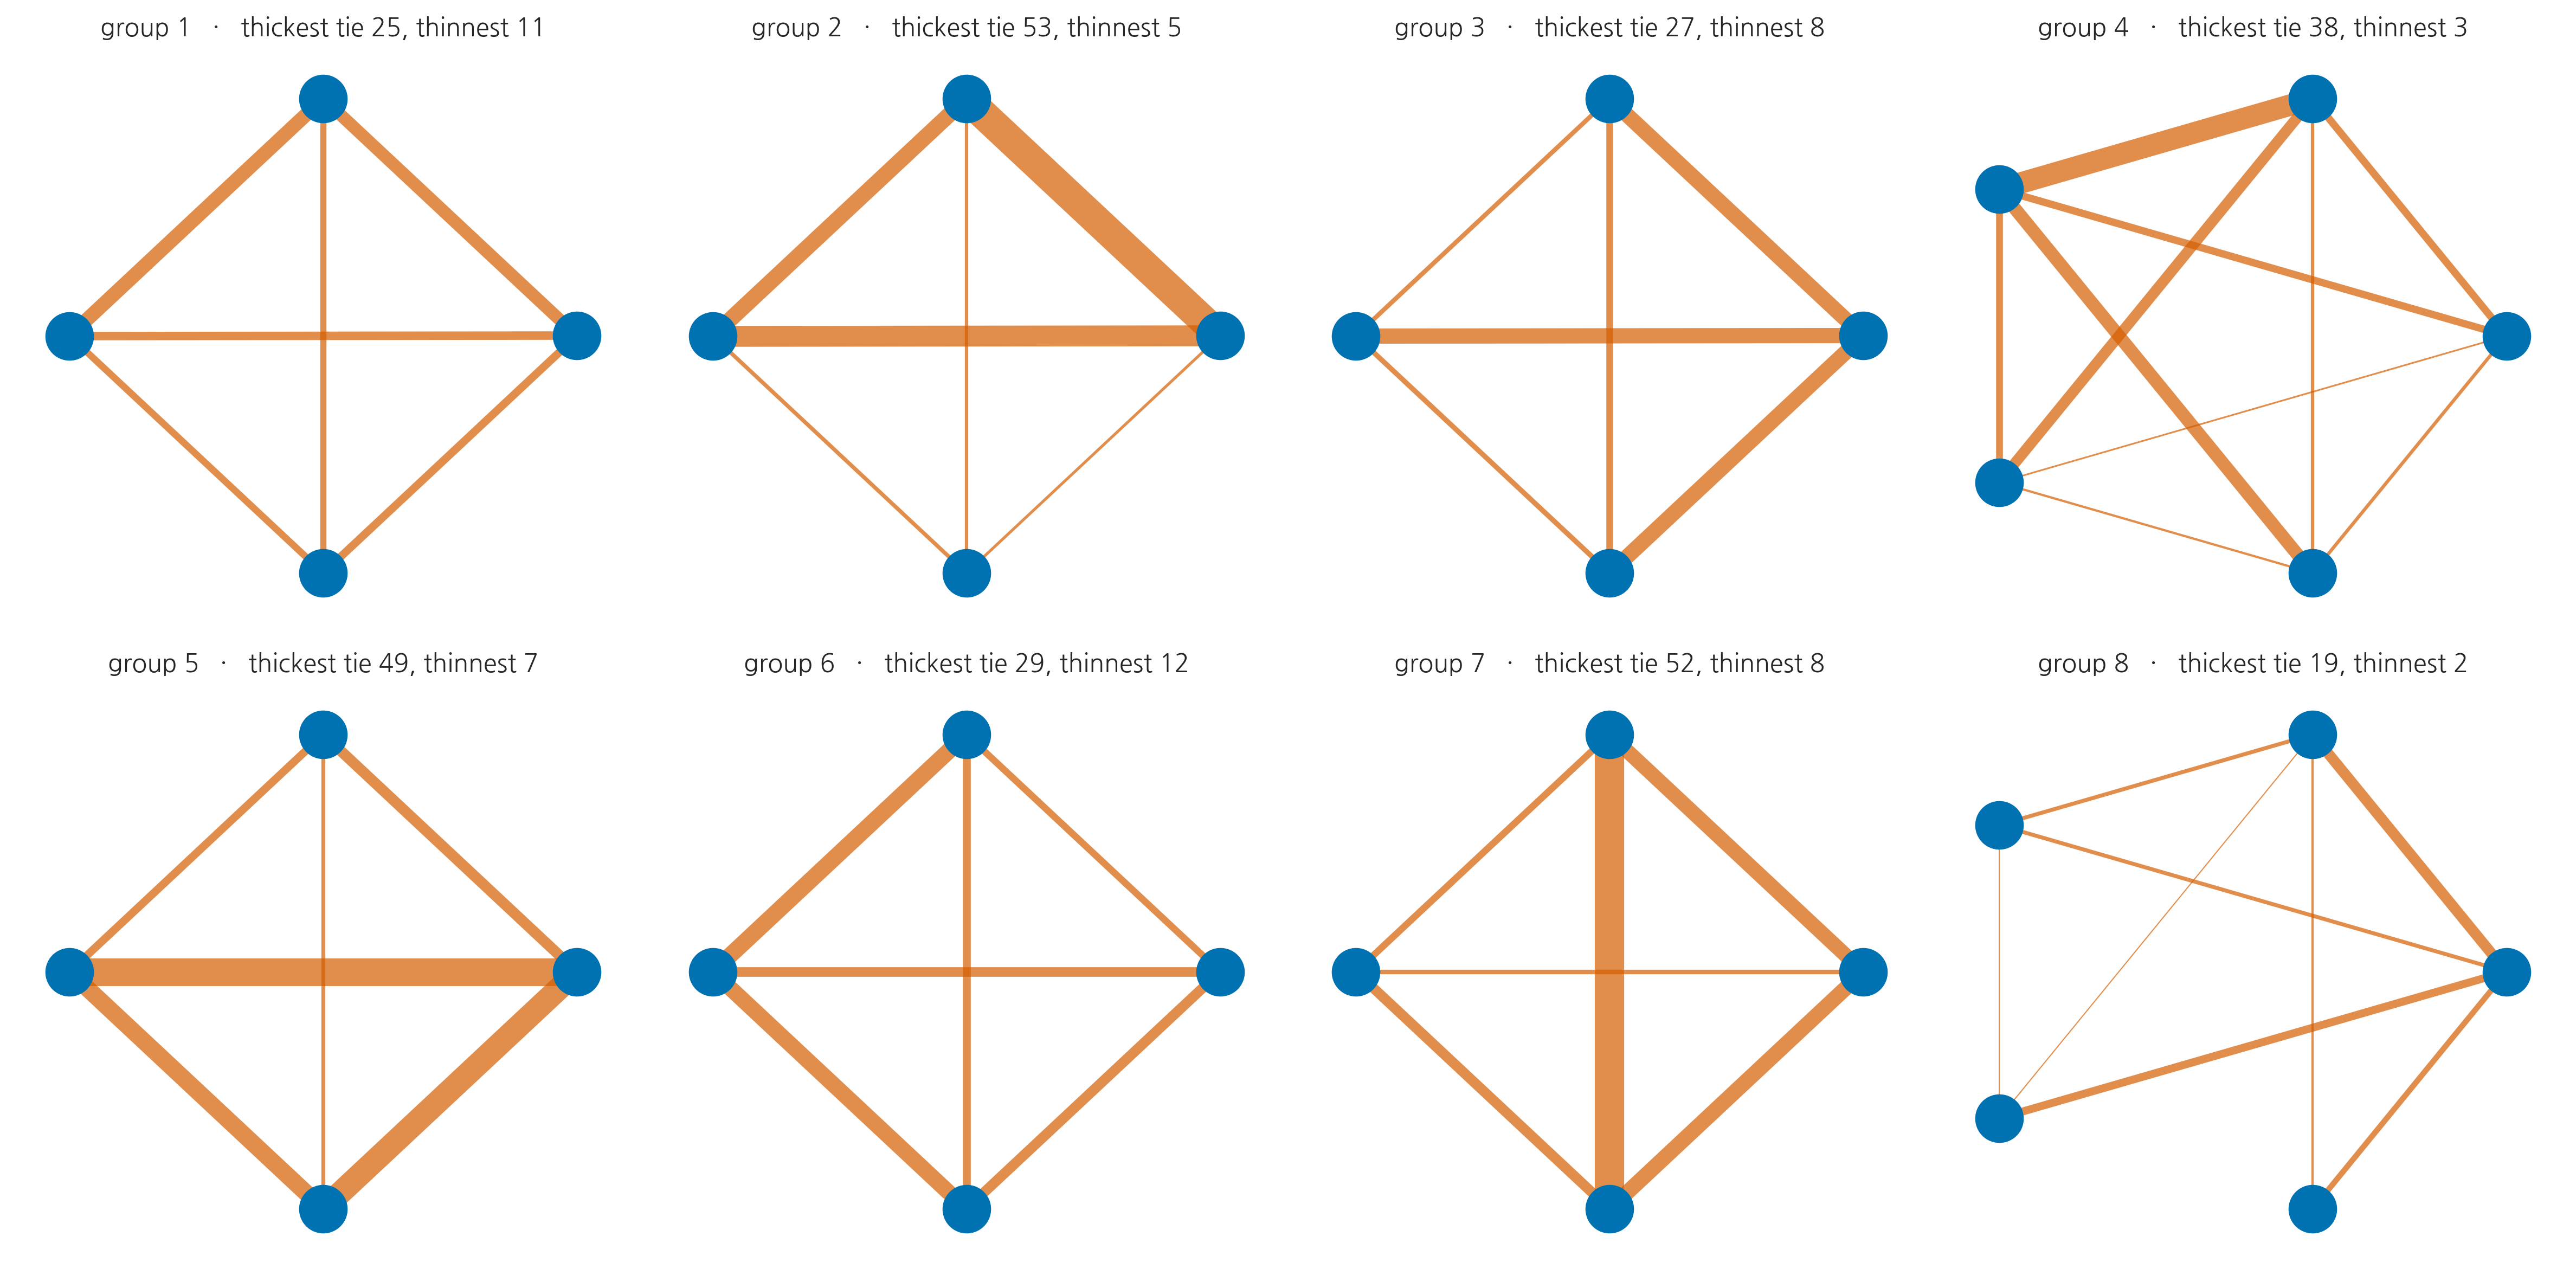

In [4]:
def ties_weighted(sub):
    w = {}
    for a, b in zip(sub.author[:-1], sub.author[1:]):
        if a != b:
            k = tuple(sorted((a, b)))
            w[k] = w.get(k, 0) + 1
    G = nx.Graph()
    G.add_nodes_from(sub.author.unique())
    for (a, b), n in w.items():
        G.add_edge(a, b, weight=n)
    return G

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (g, sub) in zip(axes.ravel(), chat.groupby("group")):
    G = ties_weighted(sub.reset_index(drop=True))
    pos = nx.circular_layout(G)
    w = [G[a][b]["weight"] for a, b in G.edges()]
    nx.draw_networkx_edges(G, pos, ax=ax, width=[x / 4 for x in w], edge_color="#d55e00", alpha=.7)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color="#0072b2", node_size=420)
    ax.set_title(f"group {g}   ·   thickest tie {max(w)}, thinnest {min(w)}", fontsize=11)
    ax.axis("off")
plt.tight_layout(); plt.show()

**Now what do you notice?**

Same people, same hour, same conversation. Only the rule changed.

## 3. Measure it

**Strength** = how many times you spoke right after someone, added up over everyone you are tied to.

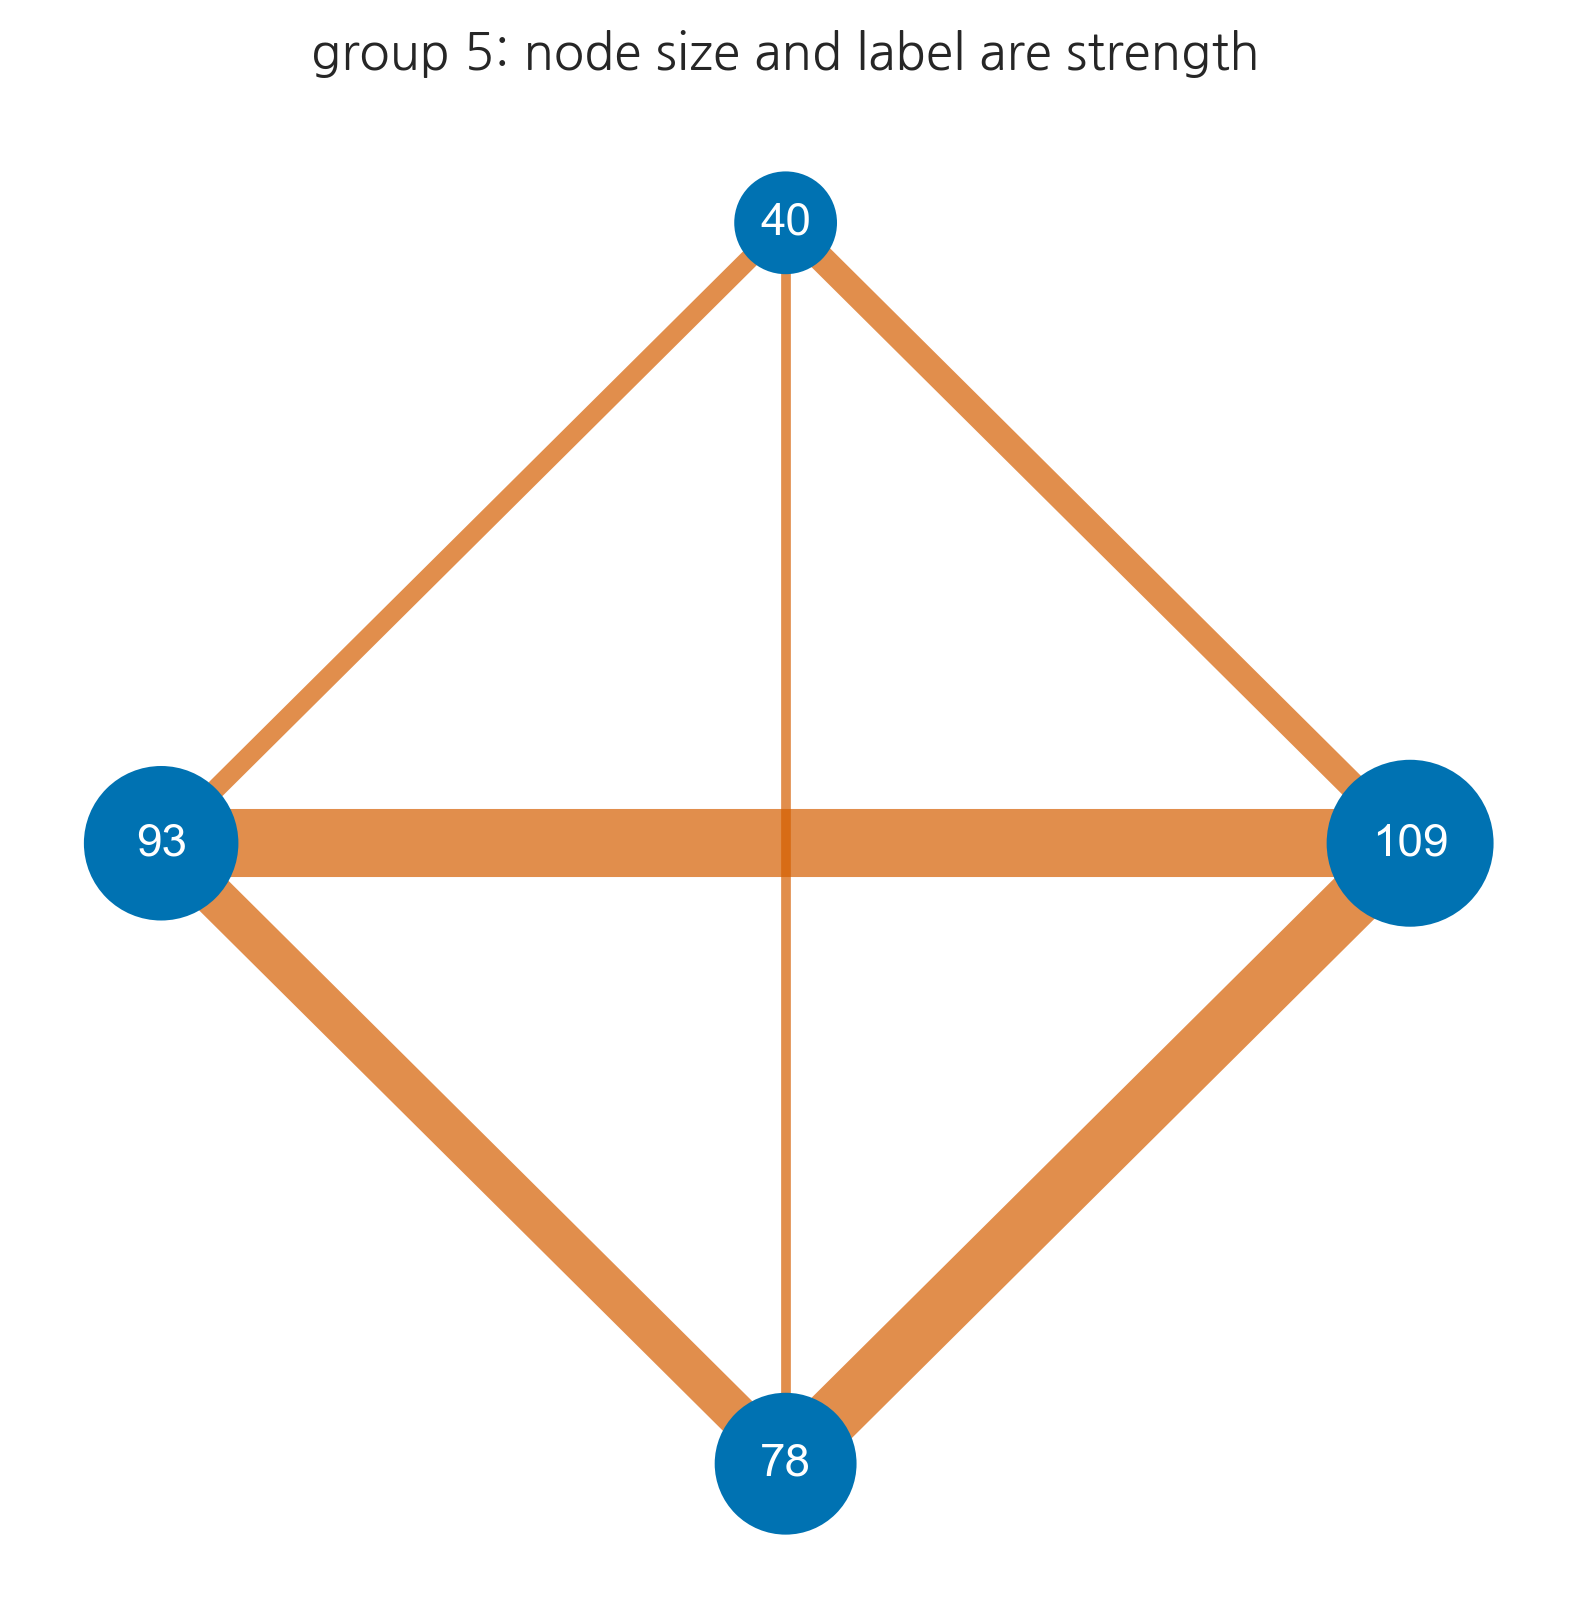

,strength,messages sent
a.w2Nla2Nd0pZ5etpv,109,123
a.wUOrpgDPYaBav65K,93,66
a.3DkI8W4m4wDUgaff,78,47
a.lzeNEP2tFJmCcuSg,40,24


In [5]:
GROUP = 5          # change this to any group from 1 to 8

sub = chat[chat.group == GROUP].reset_index(drop=True)
G = ties_weighted(sub)
strength = dict(nx.degree(G, weight="weight"))
msgs = sub.author.value_counts().to_dict()

pos = nx.circular_layout(G)
w = [G[a][b]["weight"] for a, b in G.edges()]
fig, ax = plt.subplots(figsize=(6.5, 6.5))
nx.draw_networkx_edges(G, pos, ax=ax, width=[x / 3 for x in w], edge_color="#d55e00", alpha=.7)
nx.draw_networkx_nodes(G, pos, ax=ax, node_color="#0072b2",
                       node_size=[strength[n] * 14 for n in G.nodes()])
nx.draw_networkx_labels(G, pos, {n: str(strength[n]) for n in G.nodes()},
                        font_color="white", font_size=11, ax=ax)
ax.set_title(f"group {GROUP}: node size and label are strength", fontsize=12); ax.axis("off")
plt.show()

display(pd.DataFrame({"strength": strength, "messages sent": msgs})
        .sort_values("strength", ascending=False))

## 4. Is that a network finding?

Poquet and Joksimovic (2022) argue that centrality in online learner interaction is often a proxy for how active someone was, not for their position among others.

Test it. Across all eight groups, does strength tell you anything that counting messages did not?

,group,"spearman, strength vs messages"
0,1,0.32
1,2,0.80
2,3,0.80
3,4,0.70
4,5,1.00
5,6,0.80
6,7,1.00
7,8,0.97


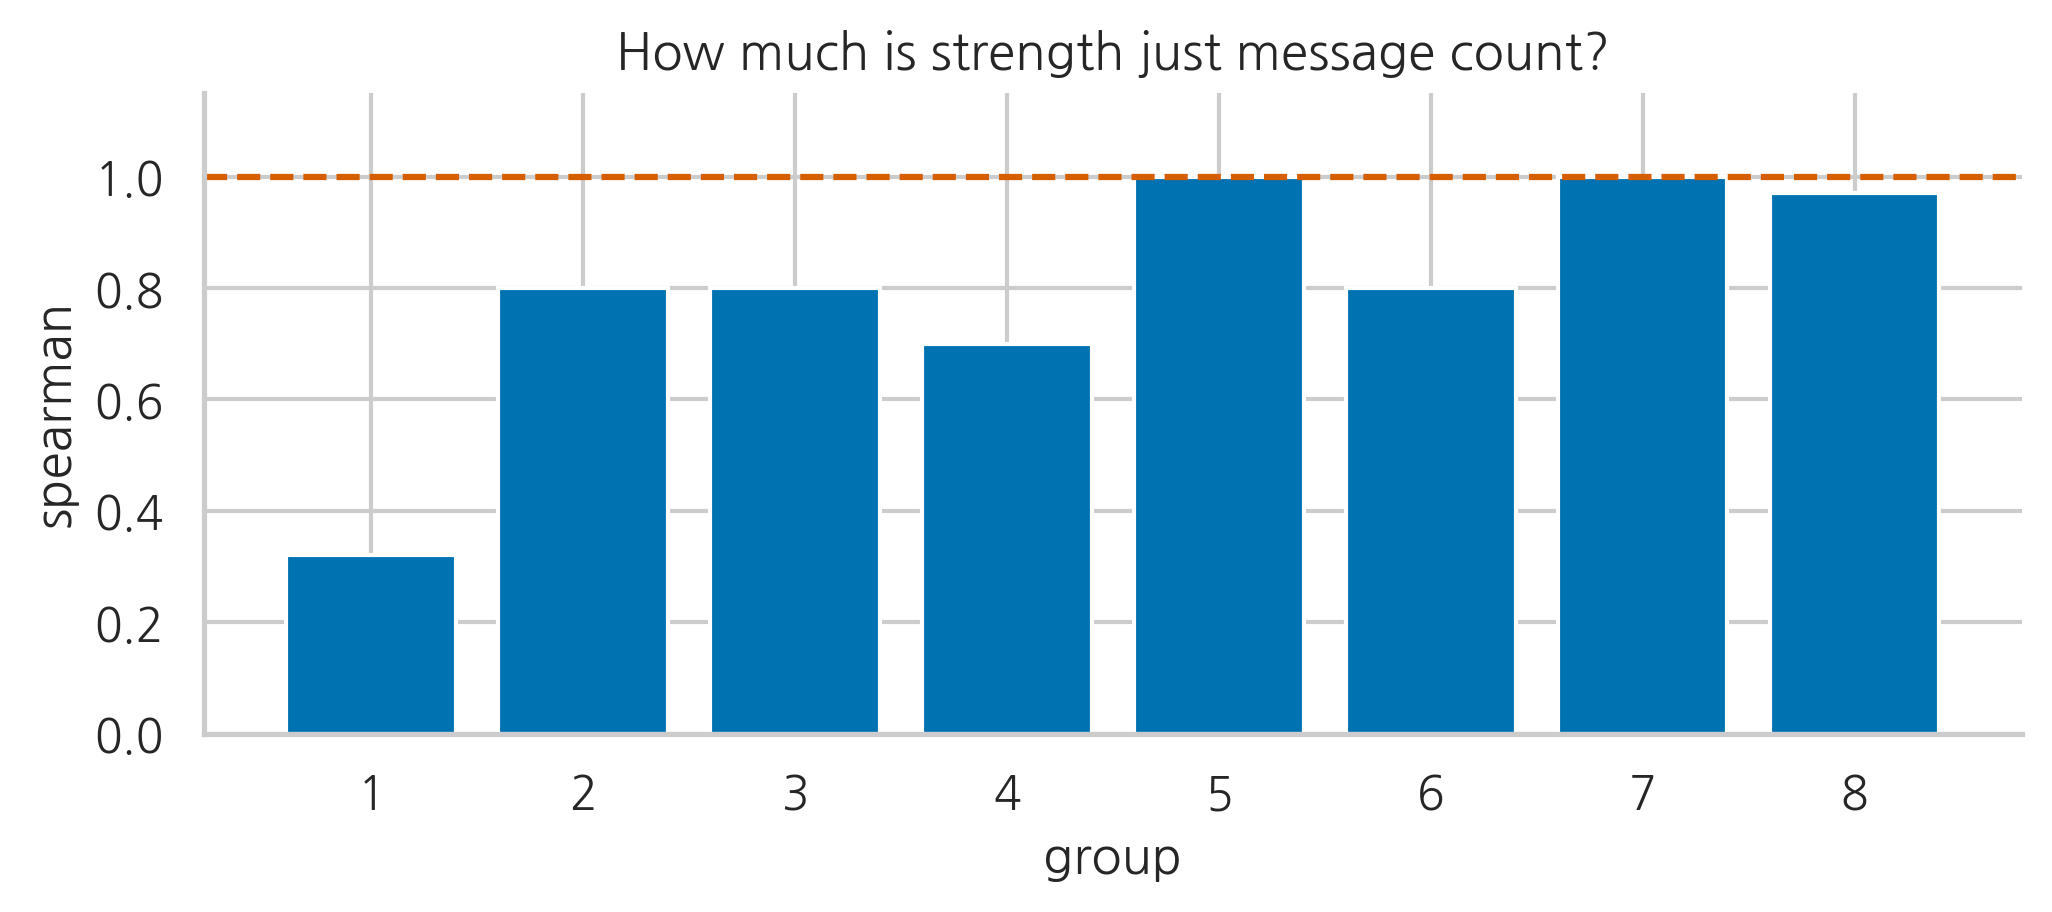

In [6]:
rows = []
for g, sub in chat.groupby("group"):
    sub = sub.reset_index(drop=True)
    G = ties_weighted(sub)
    s = pd.Series(dict(nx.degree(G, weight="weight")))
    m = sub.author.value_counts().reindex(s.index).fillna(0)
    rows.append({"group": g, "spearman, strength vs messages": round(s.corr(m, method="spearman"), 2)})
corr = pd.DataFrame(rows)
display(corr)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(corr.group, corr["spearman, strength vs messages"], color="#0072b2")
ax.axhline(1.0, color="#d55e00", ls="--")
ax.set_ylim(0, 1.15); ax.set_xlabel("group"); ax.set_ylabel("spearman")
ax.set_title("How much is strength just message count?", fontsize=12)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

Change the tie rule and see whether the answer changes. This one ties two people when one speaks within a chosen number of minutes of the other.

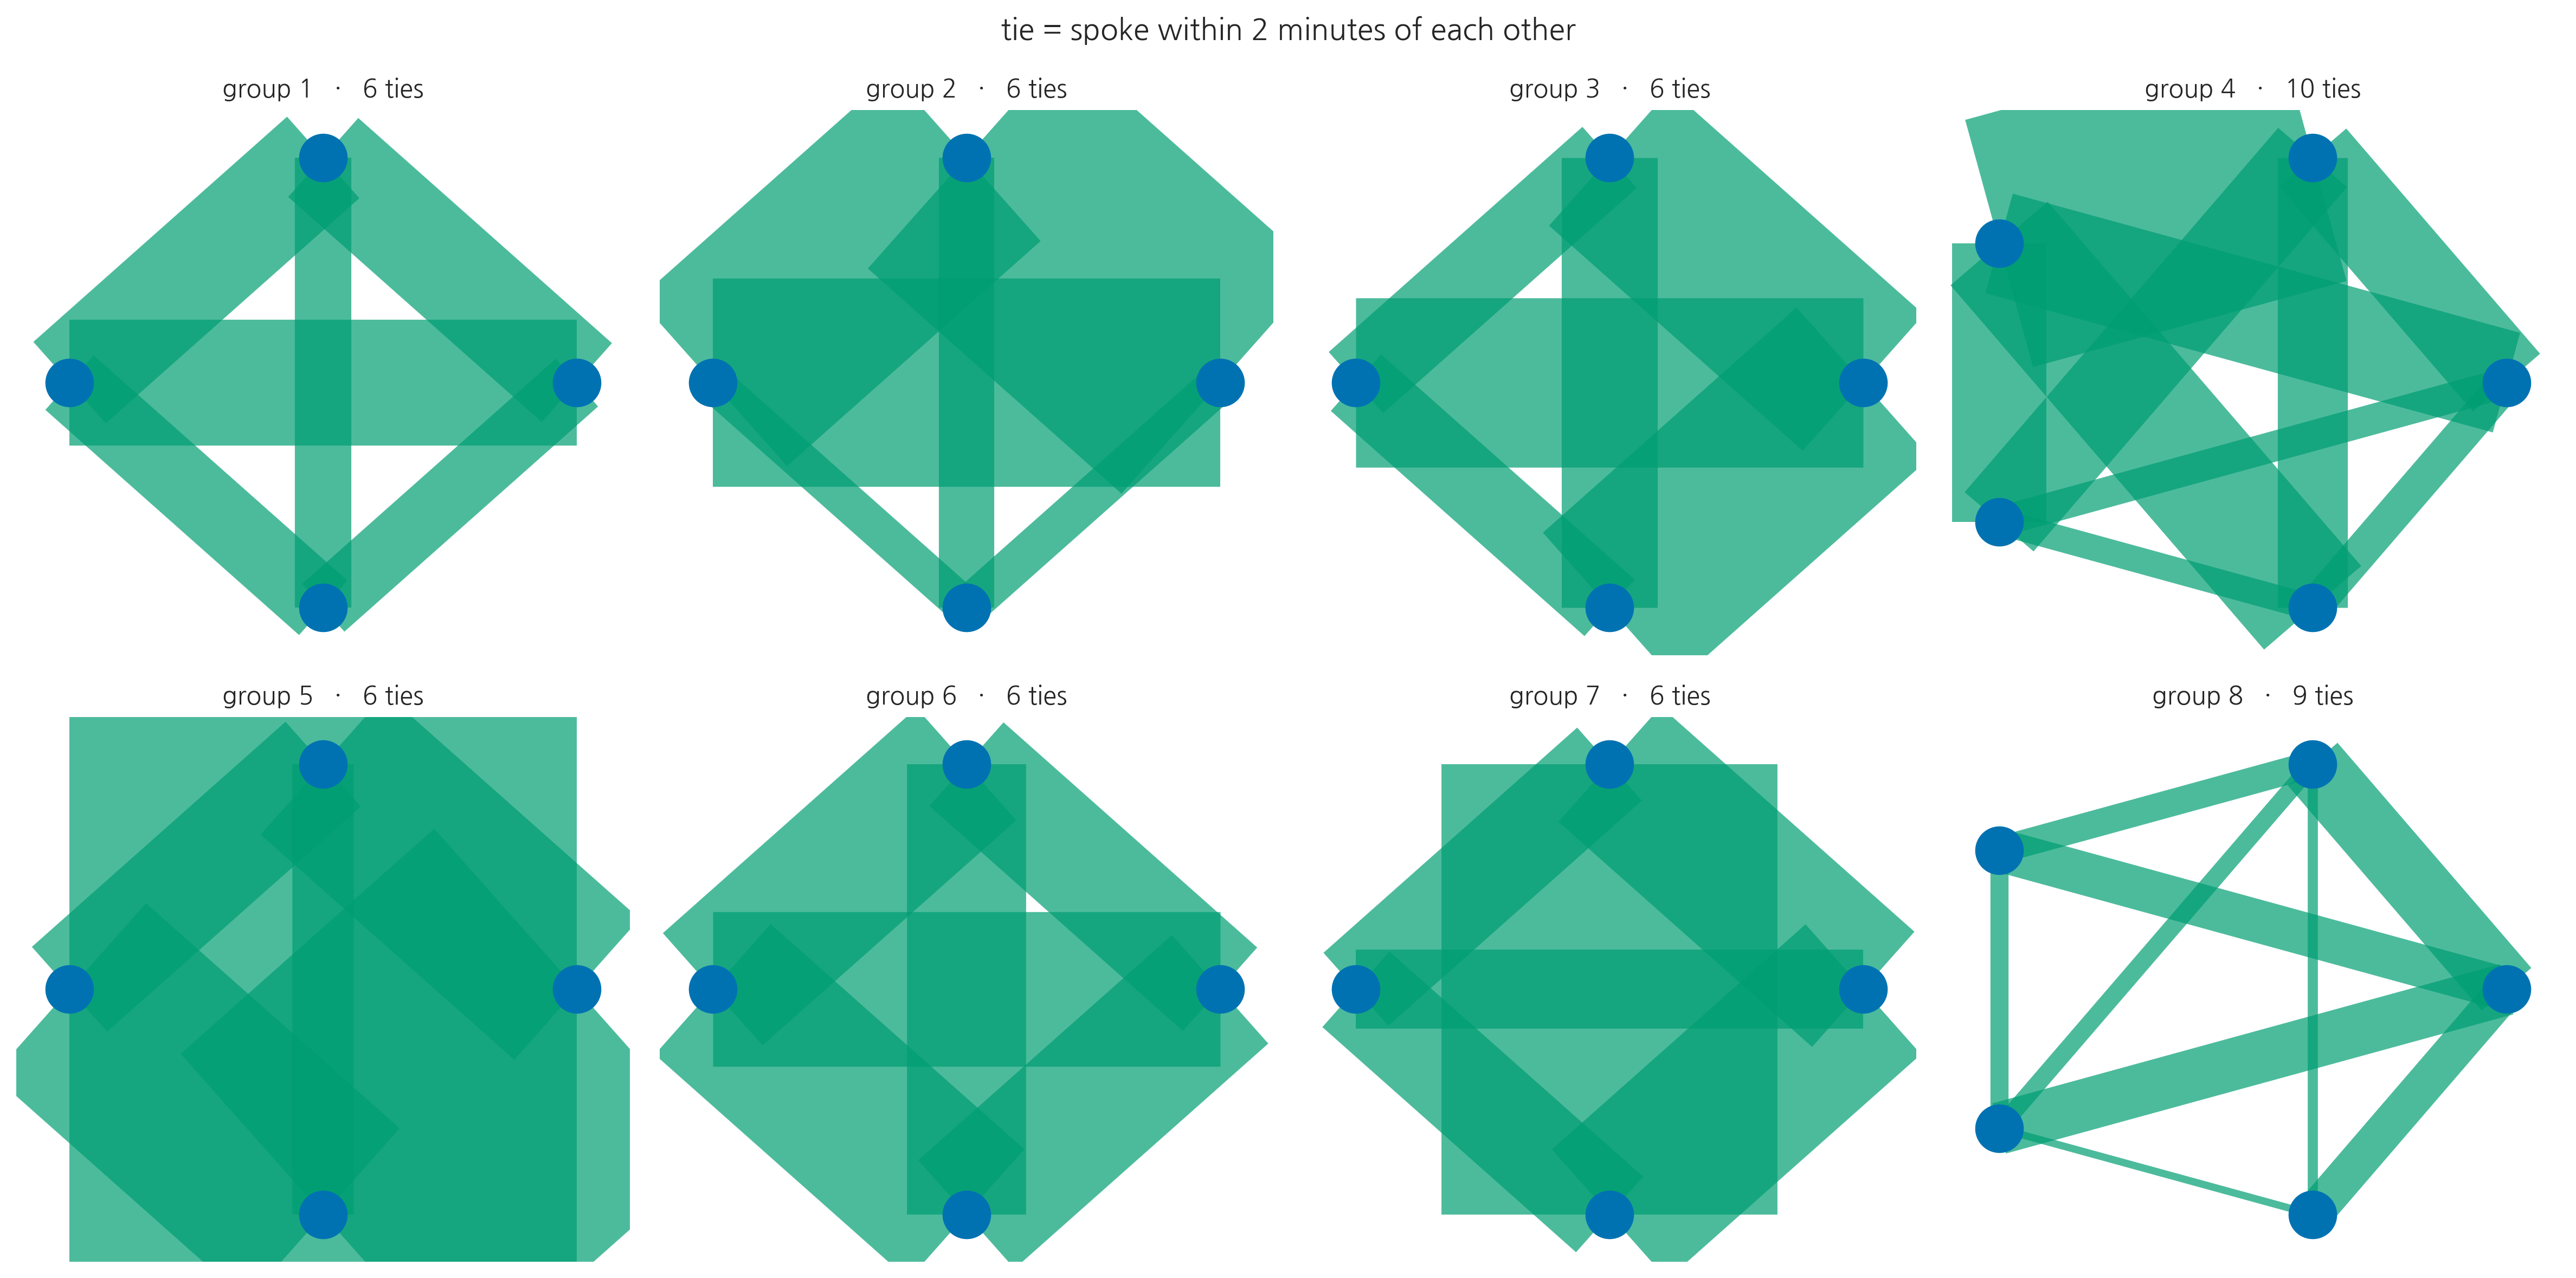

In [7]:
MINUTES = 2        # change this

chat["t"] = pd.to_datetime(chat.timestamp, format="%d/%m/%Y %H:%M")

def ties_window(sub, minutes):
    w = {}
    for i in range(len(sub) - 1):
        for j in range(i + 1, len(sub)):
            gap = (sub.t[j] - sub.t[i]).total_seconds() / 60
            if gap > minutes:
                break
            a, b = sub.author[i], sub.author[j]
            if a != b:
                k = tuple(sorted((a, b)))
                w[k] = w.get(k, 0) + 1
    G = nx.Graph(); G.add_nodes_from(sub.author.unique())
    for (a, b), n in w.items():
        G.add_edge(a, b, weight=n)
    return G

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (g, sub) in zip(axes.ravel(), chat.groupby("group")):
    G = ties_window(sub.reset_index(drop=True), MINUTES)
    pos = nx.circular_layout(G)
    if G.number_of_edges():
        w = [G[a][b]["weight"] for a, b in G.edges()]
        nx.draw_networkx_edges(G, pos, ax=ax, width=[x / 4 for x in w], edge_color="#009e73", alpha=.7)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color="#0072b2", node_size=420)
    ax.set_title(f"group {g}   ·   {G.number_of_edges()} ties", fontsize=11); ax.axis("off")
fig.suptitle(f"tie = spoke within {MINUTES} minutes of each other", fontsize=13)
plt.tight_layout(); plt.show()

## Read the conversation

The networks are built from who spoke when. None of it used what they said.

In [8]:
GROUP = 5
sub = chat[chat.group == GROUP].reset_index(drop=True)
top = max(dict(nx.degree(ties_weighted(sub), weight="weight")).items(), key=lambda kv: kv[1])[0]

print(f"group {GROUP}, strongest person: {top}\n")
for m in sub[sub.author == top].message.head(25):
    print(" ", m)

group 5, strongest person: a.w2Nla2Nd0pZ5etpv

  what's up
  mate
  do you see the stuff above?
  the solutions thing
  ?
  Okay, those are mine
  hey
  wow
  all my colors have changed
  suddenly
  now let's discuss
  which questions are we going to ask
  RT
  as many as we want yes
  hahahaa
  in case he didn't understand it
  Okay, I can see we tend to agree on two
  the average occupancy one
  and the one about how the hotel rooms are distributed
  works for me
  I mean I think it's a good question
  What do we put, like: do you need symmetry in the network or not
  Yesss it does matter
  quite a lot actually
  he doesn't know, but anyway, roughly, it's the one that will serve the guests


**Three questions.**

1. Does the strongest person look like the most important person in the conversation?
2. The first rule gave complete graphs. The second gave structure. Neither is wrong. What decides which one you use?
3. What happened in these groups that none of these networks can see?